In [63]:
import sys
sys.path.insert(0, './code')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
import cv2 as cv
%matplotlib widget

# Kalibrace

<>:77: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:77: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\ondra\AppData\Local\Temp\ipykernel_31980\842143637.py:77: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  cbar.set_label("Reprojection error $\Delta$ [pixels]", fontsize=12)


P =  [[-6.96589521e+01 -4.71026729e+03  1.02032640e+03 -1.12200834e+03]
 [-4.65533017e+03  3.11209418e+01  6.68672290e+02  7.13168161e+02]
 [-6.41830233e-02  2.46744326e-02  9.97633055e-01 -1.14815264e+00]]
K =  [[-4.73406801e+03  3.47132230e+00  9.06159092e+02]
 [-0.00000000e+00 -4.60280096e+03  9.66650635e+02]
 [-0.00000000e+00 -0.00000000e+00  1.00000000e+00]]
R_CB =  [[-0.00316072 -0.99969429  0.02452207]
 [-0.99793314  0.00157934 -0.06424139]
 [ 0.06418302 -0.02467443 -0.99763305]]
t_CB =  [-0.01694621  0.39606984  1.14815264]
RMS Error =  4.947346105260555
--------------------------------------------------
Positions shape: (55, 3)
Errors shape: (55,)


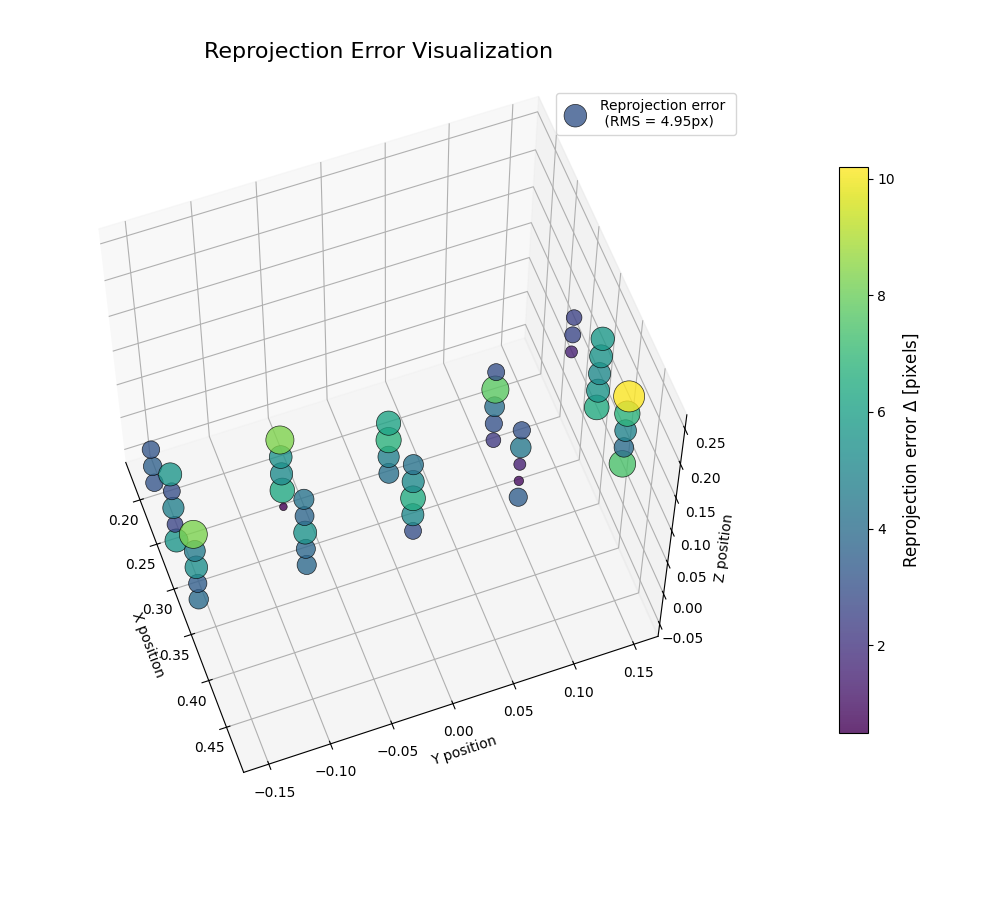

In [64]:
from camera import (
    load_camera_calibration,
    calibrate_camera,
    load_calibration_data,
    METADATA_PATH,
    CALIBRATION_PATH,
    detect_hoop_positions
)

# Load calibration data
calib_results = load_camera_calibration(path=f"./code/{CALIBRATION_PATH}")

print("P = ", calib_results["P"])
print("K = ", calib_results["K"])
print("R_CB = ", calib_results["R_CB"])
print("t_CB = ", calib_results["t_CB"])
print("RMS Error = ", calib_results["rms_error"])
print("-" * 50)

metadata, images = load_calibration_data(path=f"./code/{METADATA_PATH}")

# Extract 3D positions and reprojection errors
positions = np.array([m["translation_vector"] for m in metadata]).squeeze()

errors = np.asarray(calib_results["reprojection_errors"]).flatten()

print("Positions shape:", positions.shape)
print("Errors shape:", errors.shape)

# Make sure positions have shape (N, 3)
positions = positions.reshape(-1, 3)

# Check that every point has a corresponding error
assert len(positions) == len(errors), (
    f"Number of positions ({len(positions)}) "
    f"does not match number of errors ({len(errors)})"
)

# Normalize reprojection errors for visualization
norm = Normalize(vmin=errors.min(), vmax=errors.max())

# Map errors to colors
cmap = cm.viridis
colors = cmap(norm(errors))

# Map errors to marker sizes
# Adjust these values to change the appearance
min_size = 30
max_size = 500

if errors.max() == errors.min():
    sizes = np.full(len(errors), (min_size + max_size) / 2)
else:
    sizes = min_size + ((errors - errors.min()) / (errors.max() - errors.min())) * (
        max_size - min_size
    )

# Create interactive 3D plot
fig = plt.figure(figsize=(10, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    positions[:, 0],
    positions[:, 1],
    positions[:, 2],
    c=errors,
    cmap=cmap,
    norm=norm,
    s=sizes,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.5,
)

# Add colorbar
cbar = fig.colorbar(scatter, ax=ax, shrink=0.65, pad=0.1)
cbar.set_label("Reprojection error $\Delta$ [pixels]", fontsize=12)

# Axis labels
ax.set_xlabel("X position")
ax.set_ylabel("Y position")
ax.set_zlabel("Z position")

ax.set_title("Reprojection Error Visualization", fontsize=16, pad=20)

# Make the 3D axes have equal scale
ranges = np.ptp(positions, axis=0)
max_range = max(ranges.max(), 1e-6)

midpoints = (positions.max(axis=0) + positions.min(axis=0)) / 2

ax.set_xlim(midpoints[0] - max_range / 2, midpoints[0] + max_range / 2)
ax.set_ylim(midpoints[1] - max_range / 2, midpoints[1] + max_range / 2)
ax.set_zlim(midpoints[2] - max_range / 2, midpoints[2] + max_range / 2)

ax.set_box_aspect((0.85, 1, 1))

ax.view_init(
    elev=60,  # Elevation angle in degrees
    azim=-20,  # Azimuth angle in degrees
    roll=0,  # Rotation around the viewing axis (Matplotlib 3.6+)
)

plt.tight_layout()
plt.legend(
    handles=[scatter],
    labels=["Reprojection error \n (RMS = 4.95px)"],
    loc="upper right",
)
plt.show()

# Export as SVG
fig.savefig(
    "report_visualization_exports/3d_reprojection_errors.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.15,
    transparent=False,
)

Found 315 contours, of which 22 are larger than 50 pixels.


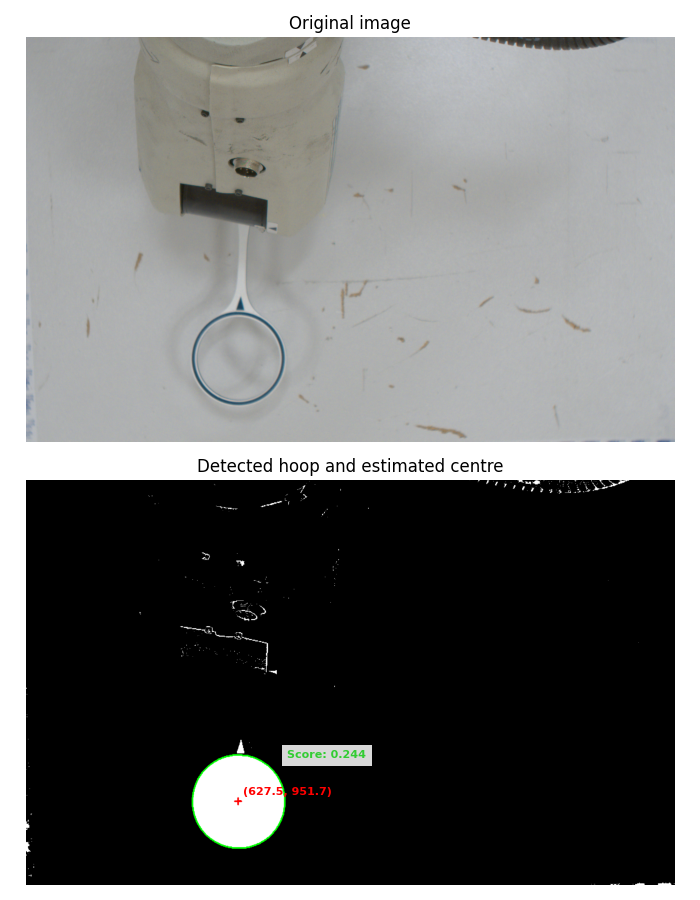

{'filepath': 'calibration_data/calibration_img_56.png', 'RPY': [-3.1415537041686337, 0.0002326615308232886, -3.1410814194797894], 'translation_vector': [0.3900527046658074, -0.08478979344565991, 0.04893553270865232]}


In [65]:
metadata, images = load_calibration_data(path=f"./code/{METADATA_PATH}")

def visualize_hoop_detection(img):
    # Detection super-parameters
    max_hue_dist = 40
    min_circle_area = 50
    minimal_roundness_deviation = 1

    # Measured hoop color samples (RGB)
    circle_color_samples = [
        (48, 84, 111),
        (52, 78, 96),
        (53, 82, 112),
        (82, 104, 135),
        (88, 105, 117),
        (83, 111, 137)
    ]

    target_color_rgb = np.mean(
        circle_color_samples, axis=0
    ).astype(np.uint8)

    target_color_hsv = cv.cvtColor(
        target_color_rgb.reshape(1, 1, 3),
        cv.COLOR_RGB2HSV
    ).reshape(3,)

    lower_color_bound = np.array([
        max(0, int(target_color_hsv[0]) - max_hue_dist),
        50,
        50
    ])

    upper_color_bound = np.array([
        min(179, int(target_color_hsv[0]) + max_hue_dist),
        255,
        255
    ])

    # Convert original image from BGR to HSV
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

    # Generate binary mask
    mask = cv.inRange(
        hsv,
        lower_color_bound,
        upper_color_bound
    )
    
    kernel = np.ones((3,3), np.uint8)
    # Fill small gaps and smooth boundaries
    mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, kernel)

    # Find contours
    contours_all, hierarchy = cv.findContours(
        mask.copy(),
        cv.RETR_EXTERNAL,
        cv.CHAIN_APPROX_SIMPLE
    )

    contours = [
        c for c in contours_all
        if cv.contourArea(c) > min_circle_area
    ]

    print(
        f"Found {len(contours_all)} contours, "
        f"of which {len(contours)} are larger than "
        f"{min_circle_area} pixels."
    )

    # Calculate roundness deviation
    def roundness_deviation(c):
        area = cv.contourArea(c)
        perimeter = cv.arcLength(c, True)
        
        return abs(
            4 * np.pi * area / (perimeter**2 + 1e-8) - 1
        )

    passing_contours = [
        c for c in contours
        if roundness_deviation(c) < minimal_roundness_deviation
    ]

    if len(passing_contours) == 0:
        raise Exception("No sufficiently good circle has been found!")

    # Select the most circular contour
    best = min(passing_contours, key=roundness_deviation)

    # Calculate its centre (same method as original function)
    center = np.mean(best.reshape(-1, 2), axis=0)

    # Create visualization of all detected contours
    contour_mask = np.zeros_like(mask)
    cv.drawContours(
        contour_mask,
        contours_all,
        -1,
        color=255,
        thickness=cv.FILLED
    )

    # Draw selected contour in green
    contour_overlay = cv.cvtColor(
        contour_mask, cv.COLOR_GRAY2RGB
    )

    cv.drawContours(
        contour_overlay,
        [best],
        -1,
        color=(0, 255, 0),
        thickness=3
    )

    # Draw centre as a red cross
    cx, cy = np.round(center).astype(int)

    cv.drawMarker(
        contour_overlay,
        (cx, cy),
        color=(255, 0, 0),
        markerType=cv.MARKER_CROSS,
        markerSize=20,
        thickness=3
    )

    # Calculate roundness deviation
    area = cv.contourArea(best)
    perimeter = cv.arcLength(best, True)
    roundness = 1 - (4 * np.pi * area / (perimeter**2 + 1e-8))

    # Calculate bounding box of selected contour
    x, y, w, h = cv.boundingRect(best)

    # Plot side by side
    fig, axes = plt.subplots(2, 1, figsize=(7, 9))

    # Left: Original image
    axes[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    axes[0].set_title("Original image")
    axes[0].axis("off")

    # Right: Contour visualization
    axes[1].imshow(contour_overlay)
    axes[1].set_title("Detected hoop and estimated centre")
    axes[1].axis("off")

    # Centre coordinates
    cx, cy = center

    # Add coordinates next to the red centre marker
    axes[1].annotate(
        f"({cx:.1f}, {cy:.1f})",
        xy=(cx, cy),
        xytext=(cx + 15, cy - 20),
        color="red",
        fontsize=8,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-", color="red", lw=1),
        bbox=dict(facecolor="none", alpha=0.8, edgecolor="none", pad=3)
    )

    # Add roundness deviation next to the circle
    axes[1].text(
        x + w + 8,
        y ,
        f"Score: {roundness:.3f}",
        color="limegreen",
        fontsize=8,
        fontweight="bold",
        va="center",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=4)
    )

    plt.tight_layout()
    plt.show()


    return center, best, mask

visualize_hoop_detection(images[35])
print(metadata[35])
plt.savefig(
    "report_visualization_exports/hoop_detection.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.15,
    transparent=False,
)